In [7]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

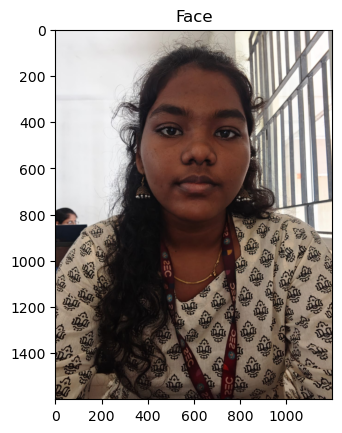

In [8]:
# Load the Face Image
faceImage = cv2.imread('janani.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [9]:
faceImage.shape

(1600, 1200, 3)

### resized_faceImage.shape
faceImage.shape

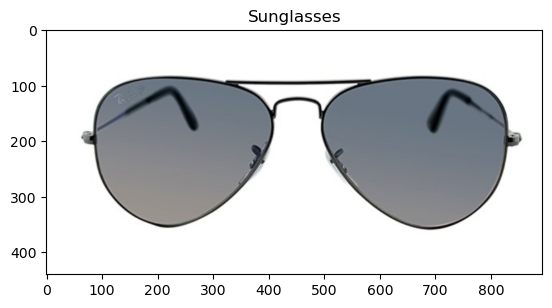

In [10]:
glassPNG = cv2.imread('sunglass.png', cv2.IMREAD_UNCHANGED)

plt.imshow(cv2.cvtColor(glassPNG, cv2.COLOR_BGRA2RGBA))
plt.title("Sunglasses")
plt.show()

In [22]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [29]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

In [39]:
gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

_, glassMask1 = cv2.threshold(gray, 200, 255, cv2.THRESH_BINARY_INV)

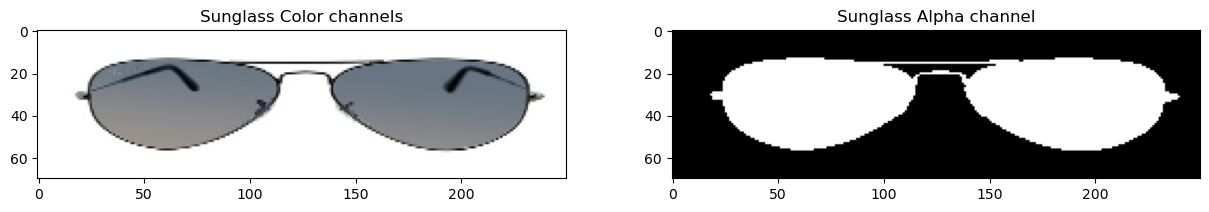

In [40]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

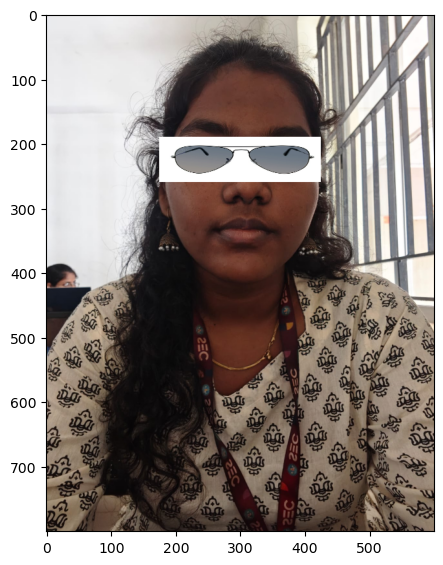

In [43]:
# Resize face image
resized_faceImage = cv2.resize(faceImage, (600, 800))

# Resize sunglasses
glassPNG = cv2.resize(glassPNG, (250, 70))
glassBGR = glassPNG[:, :, :3]

# Copy resized face
faceWithGlassesNaive = resized_faceImage.copy()

# Place sunglasses
faceWithGlassesNaive[190:260, 175:425] = glassBGR

# Display
plt.figure(figsize=(5, 7))
plt.imshow(faceWithGlassesNaive[:, :, ::-1])
plt.show()

NameError: name 'maskedEye' is not defined

# Make the dimensions of the mask same as the input image.
# Since Face Image is a 3-channel image, we create a 3 channel image for the mask
glassMask = cv2.merge((glassMask1,glassMask1,glassMask1))

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask/255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region from the face image
eyeROI= faceWithGlassesArithmetic[135:185,110:300]

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI,(1-  glassMask ))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR,glassMask)

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=[20,20])
plt.subplot(131);plt.imshow(maskedEye[...,::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[...,::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[...,::-1]);plt.title("Augmented Eye and Sunglass")

In [42]:
faceWithGlassesArithmetic[190:260, 175:425] = eyeRoiFinal

plt.figure(figsize=(10, 8))

plt.subplot(121)
plt.imshow(resized_faceImage[:, :, ::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")

plt.show()

NameError: name 'eyeRoiFinal' is not defined